# 01 - Data Cleaning: APTOS 2019

**Goal:** audit the raw images before any preprocessing. We remove unusable images and duplicates, and flag unusual images for visual review.

**Why this comes first:** APTOS contains exact duplicate photos, some with contradictory grades. If copies end up on both sides of a train/validation split, the validation scores are inflated. Cleaning must therefore happen **before** preprocessing and splitting.

**Produced by:** `python -m src.clean_data` (rules documented in the docstring of `src/clean_data.py`).
**Outputs:** `data/image_report.csv` (all measurements and decisions) and `data/clean.csv` (kept images).

## 1. Loading the audit report

`image_report.csv` has one row per raw image, with its measurements (size, brightness, sharpness, hash) and the decision of each cleaning rule.

In [24]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../data"
rep = pd.read_csv(f"{DATA}/image_report.csv")

print("Rows in report:", len(rep))
print("Images kept:   ", rep["keep"].sum())
rep.head()

Rows in report: 3662
Images kept:    3504


,id_code,diagnosis,readable,width,height,retina_frac,brightness,blur,hash,bad_unreadable,bad_small,bad_empty,dup_conflict,dup_extra,manual_exclude,keep,flag_dark,flag_bright,flag_blurry,flag_low_retina
0,000c1434d8d7,2,True,3216,2136,0.746294,60.748177,48.872904,9b6494a7979a8d426a626c687044f430,False,False,False,False,False,False,True,False,False,False,False
1,001639a390f0,4,True,3216,2136,0.746919,88.057438,34.360972,a5c8ef1f23d1d4d5a34fb49426630c73,False,False,False,False,False,False,True,False,False,False,False
2,0024cdab0c1e,1,True,2416,1736,0.833393,71.044872,47.928621,9f70ef5ab13d75d2cff8a4400e02cc6b,False,False,False,False,False,False,True,False,False,False,False
3,002c21358ce6,0,True,1050,1050,0.791934,85.489552,59.879396,44f83e7592fddb29b89f35145dafa5be,False,False,False,False,False,False,True,False,False,False,False
4,005b95c28852,0,True,2048,1536,0.474331,33.940788,29.975228,21f2eaf58fa722c21d2b8fd9b074b924,False,False,False,False,False,False,True,False,False,False,False


**Interpretation:** the report covers all raw images, and 3,504 of them are kept. Each row also records why an image was removed (if it was), so every decision can be traced.

## 2. How many images were removed, and why?

Rules applied in order: unreadable file, too small (shorter side under 256 px), empty (under 5% non-black pixels), duplicates with conflicting labels (all copies removed), duplicates with the same label (one copy kept), manual exclusions.

In [20]:
rules = ["bad_unreadable", "bad_small", "bad_empty", "dup_conflict", "dup_extra", "manual_exclude"]
summary = rep[rules].sum().rename("images").to_frame()
summary.loc["KEPT"] = rep["keep"].sum()
summary.loc["TOTAL"] = len(rep)
summary

,images
bad_unreadable,0
bad_small,0
bad_empty,0
dup_conflict,62
dup_extra,96
manual_exclude,0
KEPT,3504
TOTAL,3662


**Interpretation**
- **No unreadable, tiny or empty files:** the raw data is technically healthy.
- All removals come from duplicates: **62 images** belong to duplicate groups with conflicting labels (all copies removed), and **96 images** are extra copies of consistent groups (one copy kept).
- **3,662 - 62 - 96 = 3,504 images kept.** This matches the independent duplicate analysis done earlier.

## 3. Duplicates with contradictory labels

For each group of identical images whose copies carry different grades, which grades are confused?

In [4]:
conf = rep[rep["dup_conflict"]]
groups = conf.groupby("hash")["diagnosis"].apply(lambda s: ",".join(map(str, sorted(s))))

print("Conflicting groups:", len(groups))
print("Images in them:    ", len(conf))
print()
print(groups.value_counts())

Conflicting groups: 30
Images in them:     62

diagnosis
2,3      8
2,4      8
1,2      4
0,1      4
3,4      3
1,2,2    1
1,4      1
2,3,3    1
Name: count, dtype: int64


**Interpretation:**  In the earlier analysis there were **30 conflicting groups**: 21 differ by one grade (2 vs 3 and 2 vs 4 are the most frequent pairs), 8 by two grades and 1 by three grades. Grade 2 appears in most conflicts, so annotators disagree mostly at the boundaries between neighboring grades. This is **label noise inside APTOS itself**, and it puts a ceiling on what any model can achieve there.

In [ ]:
h = groups.index[0]
pair = conf[conf["hash"] == h].head(2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (_, r) in zip(axes, pair.iterrows()):
    img = cv2.cvtColor(cv2.imread(f"{DATA}/train_images/{r.id_code}.png"), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{r.id_code} | grade {r.diagnosis}")
plt.suptitle("Same image, different labels")
plt.tight_layout(); plt.show()

**Interpretation:** the two files are pixel-identical but carry different grades, so at least one label is wrong. We cannot know which one, so all copies of such groups are removed instead of guessing.

## 4. Class distribution before and after cleaning

Cleaning must not change the character of the dataset. We compare the number of images per grade before and after.

          before  after  removed  removed_%
No DR       1805   1796        9        0.5
Mild         370    338       32        8.6
Moderate     999    922       77        7.7
Severe       193    177       16        8.3
Prolif.      295    271       24        8.1


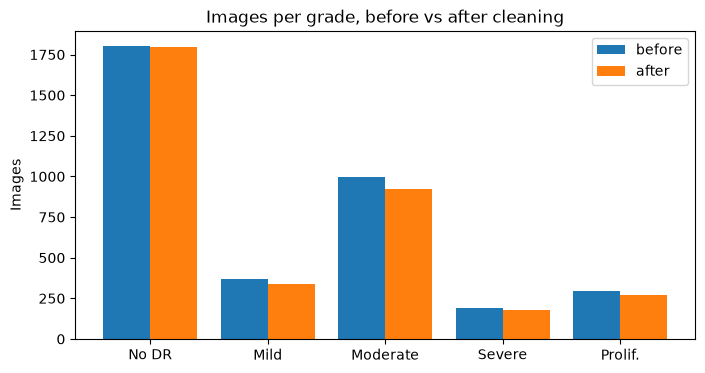

In [7]:
names = ["No DR", "Mild", "Moderate", "Severe", "Prolif."]
before = rep["diagnosis"].value_counts().sort_index()
after = rep.loc[rep["keep"], "diagnosis"].value_counts().sort_index()

tab = pd.DataFrame({"before": before, "after": after})
tab["removed"] = tab["before"] - tab["after"]
tab["removed_%"] = (100 * tab["removed"] / tab["before"]).round(1)
tab.index = names
print(tab)

x = np.arange(5)
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, before.values, 0.4, label="before")
plt.bar(x + 0.2, after.values, 0.4, label="after")
plt.xticks(x, names); plt.ylabel("Images"); plt.legend()
plt.title("Images per grade, before vs after cleaning")
plt.show()

**Interpretation**

| Grade | Before | After | Removed |
|---|---|---|---|
| 0 No DR | 1805 | 1796 | 0.5% |
| 1 Mild | 370 | 338 | 8.6% |
| 2 Moderate | 999 | 922 | 7.7% |
| 3 Severe | 193 | 177 | 8.3% |
| 4 Proliferative | 295 | 271 | 8.1% |

- Duplicates are concentrated in the disease grades (about 8% removed each), while grade 0 lost almost nothing.
- The class imbalance remains (51% grade 0, 5% grade 3), so weighted sampling is still needed.
- Grade 3 now has only 177 images, so its validation share will contain about 35 images, which makes per-grade estimates for severe DR very uncertain.

## 5. Unusual images flagged for visual review

Among the kept images, four measurements are flagged at the extreme 1%: **dark**, **bright**, **blurry** (low edge strength) and **low retina area** (large black areas). A flag only means "unusual", not "bad", and about 35 images per flag are selected by definition. Nothing is removed automatically: we look at them and exclude only images where no retina is visible.

In [8]:
flags = ["flag_dark", "flag_bright", "flag_blurry", "flag_low_retina"]
print(rep[flags].sum())
print("Unique flagged images:", rep[flags].any(axis=1).sum())

def show_flag(flag, per_page=20):
    sub = rep[rep[flag]]
    for start in range(0, len(sub), per_page):
        page = sub.iloc[start:start + per_page]
        fig, axes = plt.subplots(4, 5, figsize=(20, 16))
        for ax in axes.flat: ax.axis("off")
        for ax, (_, r) in zip(axes.flat, page.iterrows()):
            img = cv2.cvtColor(cv2.imread(f"{DATA}/train_images/{r.id_code}.png"), cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (400, int(400 * img.shape[0] / img.shape[1])))
            ax.imshow(img)
            ax.set_title(f"{r.id_code}\ngrade {r.diagnosis}", fontsize=9)
        plt.suptitle(f"{flag}: {start + 1} to {start + len(page)} of {len(sub)}")
        plt.tight_layout(); plt.show()

flag_dark          36
flag_bright        36
flag_blurry        36
flag_low_retina    36
dtype: int64
Unique flagged images: 114


### 5a. Darkest images

In [ ]:
show_flag("flag_dark")

### 5b. Brightest images

In [ ]:
show_flag("flag_bright")

### 5c. Blurriest images

In [ ]:
show_flag("flag_blurry")

### 5d. Images with the smallest retina area

In [ ]:
show_flag("flag_low_retina")

**Interpretation (visual review of the 114 flagged images)**
- **Dark:** all show a visible retina with vessels and optic disc; the darkest still show lesions (exudates). They are dim, not unusable.
- **Bright:** overexposed, orange or washed-out retinas with clear vessels and lesions. Two images show a cobblestone texture and an unusual outline, consistent with a different camera.
- **Blurry:** mostly low-contrast, dark images rather than out-of-focus ones (many also carry the dark flag). A few have camera artifacts (blue smudge or arc), but the retina is visible.
- **Low retina area:** small, well-framed retinas in a wide black frame, all labelled grade 0. The crop step in preprocessing normalizes this framing.
- **Decision:** no image was excluded (`manual_exclude.txt` is empty), since in every case a retina is visible and removing hard cases would make results look better than they really are.
- **Risk noted:** flags are not evenly spread across grades (all low-retina images are grade 0, most bright images are grade 2), so image appearance may be correlated with the label. This will be checked with Grad-CAM.

## 6. Manual exclusions

Images where no retina is visible after the review are written to `data/manual_exclude.txt` (one `id_code` per line). `python -m src.clean_data` reads this file when it is rerun.

In [13]:
exclude = []    # its empty because nothing will be removed

with open(f"{DATA}/manual_exclude.txt", "w") as f:
    f.write("\n".join(exclude))
print(f"{len(exclude)} image(s) written to manual_exclude.txt")

0 image(s) written to manual_exclude.txt


## Summary

| Aspect | Finding | Decision |
|---|---|---|
| File integrity | 0 unreadable, 0 too small, 0 empty | None needed |
| Exact duplicates | 123 groups, 251 images | One copy kept per consistent group |
| Conflicting labels | 30 groups, 62 images | All copies removed |
| Remaining dataset | **3,504 images** | Saved in `data/clean.csv` |
| Class balance | Still strongly imbalanced (51% No DR, 5% Severe) | Weighted sampling in training |
| Outliers | 114 flagged, reviewed visually | [fill in after review] |

**Limitations:** only exact duplicates are detected (not the same eye photographed twice); a single wrongly labelled image is not detectable; removing conflicting images may make the validation set slightly easier.

**Next:** preprocessing of the kept images (`src/preprocess.py`), then one stratified split from `clean.csv` with a check that train and validation share no image.